<a href="https://colab.research.google.com/github/Phan-le-my-huyen/lung_project/blob/main/03_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/lung_project'
TAR  = f'{BASE}/data/Task06_Lung.tar'
ROOT = '/content/data/Task06_Lung'

if not os.path.exists(ROOT):
    !mkdir -p /content/data
    !tar -xf "{TAR}" -C /content/data --exclude='._*'
print('Sẵn sàng:', os.path.exists(ROOT))

Mounted at /content/drive
Sẵn sàng: True


In [2]:
!pip install -q "monai[nibabel]" SimpleITK

In [3]:
import glob, os
import numpy as np, pandas as pd, nibabel as nib

imgs = sorted(glob.glob(f'{ROOT}/imagesTr/*.nii.gz'))
rows = []
for p in imgs:
    name = os.path.basename(p)
    img  = nib.load(p)
    lab  = nib.load(p.replace('imagesTr', 'labelsTr'))
    a    = img.get_fdata(dtype=np.float32)
    m    = lab.get_fdata().astype(np.uint8)
    sp   = img.header.get_zooms()
    vox_ml = float(np.prod(sp)) / 1000.0
    rows.append({
        'case': name.replace('.nii.gz', ''),
        'shape': a.shape,
        'spacing_x': round(sp[0], 3),
        'spacing_y': round(sp[1], 3),
        'spacing_z': round(sp[2], 3),
        'hu_min': float(a.min()),
        'hu_max': float(a.max()),
        'hu_mean': round(float(a.mean()), 1),
        'tumor_voxels': int((m > 0).sum()),
        'tumor_ml': round(float((m > 0).sum()) * vox_ml, 2),
    })
df = pd.DataFrame(rows)
df.to_csv(f'{BASE}/results/eda_cases.csv', index=False)
df.head()

,case,shape,spacing_x,spacing_y,spacing_z,hu_min,hu_max,hu_mean,tumor_voxels,tumor_ml
0,lung_001,"(512, 512, 304)",0.693,0.693,1.000,-1024.0,3071.0,-545.5,2719,1.31
1,lung_003,"(512, 512, 288)",0.938,0.938,1.246,-1024.0,2389.0,-616.7,1324,1.45
2,lung_004,"(512, 512, 276)",0.828,0.828,1.245,-1024.0,3071.0,-478.9,1547,1.32
3,lung_005,"(512, 512, 329)",0.654,0.654,1.000,-1024.0,3070.0,-501.7,16625,7.12
4,lung_006,"(512, 512, 567)",0.977,0.977,0.625,-1024.0,1944.0,-536.9,7050,4.20


In [4]:
print(df[['spacing_x', 'spacing_y', 'spacing_z']].describe().round(3))
print()
print(df[['hu_min', 'hu_max', 'tumor_ml']].describe().round(1))
print('\nSố loại kích thước ảnh:', df['shape'].nunique())

       spacing_x  spacing_y  spacing_z
count     63.000     63.000     63.000
mean       0.794      0.794      1.314
std        0.083      0.083      0.492
min        0.598      0.598      0.625
25%        0.766      0.766      1.244
50%        0.785      0.785      1.245
75%        0.844      0.844      1.246
max        0.977      0.977      2.500

       hu_min   hu_max  tumor_ml
count    63.0     63.0      63.0
mean  -1024.0   3157.9      22.0
std       0.0   2243.1      52.1
min   -1024.0   1525.0       0.7
25%   -1024.0   3070.5       2.7
50%   -1024.0   3071.0       5.2
75%   -1024.0   3071.0      15.9
max   -1024.0  20349.0     370.4

Số loại kích thước ảnh: 52


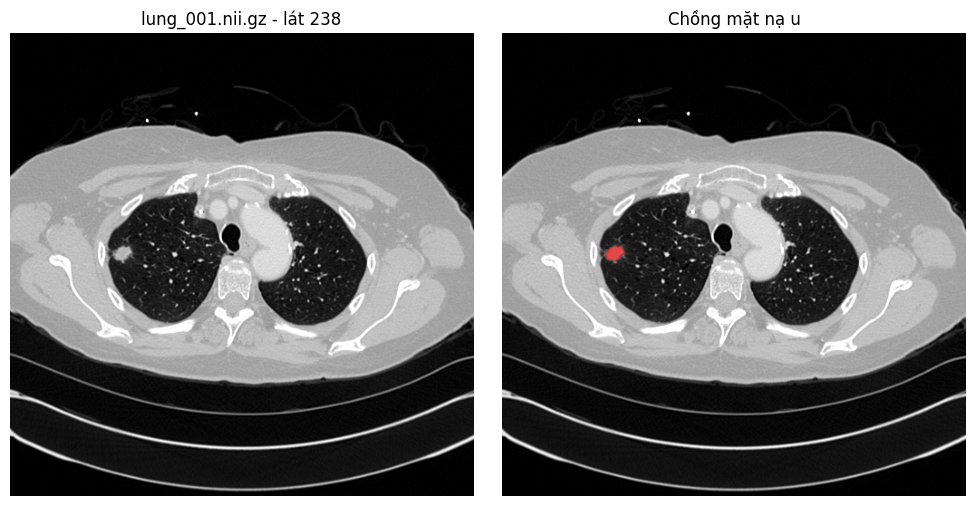

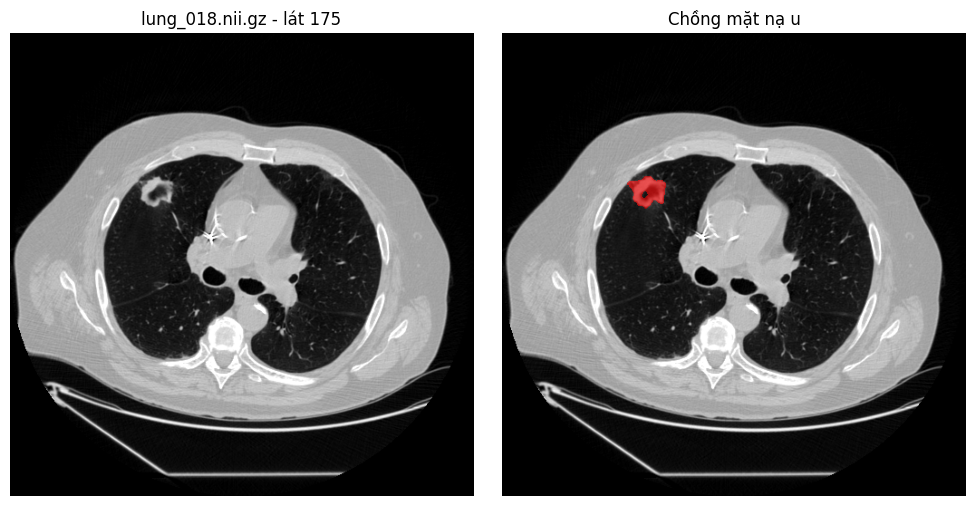

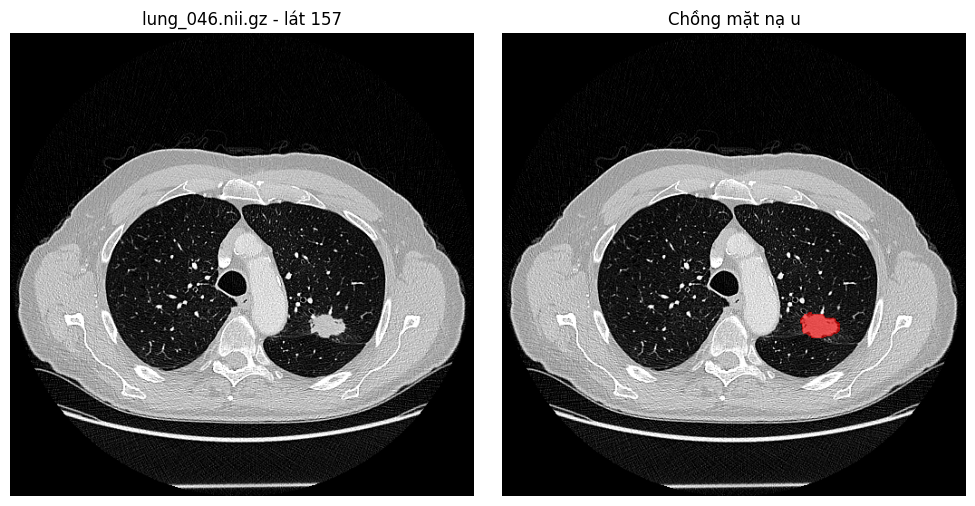

In [5]:
import matplotlib.pyplot as plt

def show_case(i):
    p   = imgs[i]
    a   = nib.load(p).get_fdata()
    m   = nib.load(p.replace('imagesTr', 'labelsTr')).get_fdata()
    z   = int(np.argmax((m > 0).sum(axis=(0, 1))))
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(np.clip(a[:, :, z], -1000, 400).T, cmap='gray', origin='lower')
    ax[0].set_title(f'{os.path.basename(p)} - lát {z}')
    ax[1].imshow(np.clip(a[:, :, z], -1000, 400).T, cmap='gray', origin='lower')
    ax[1].imshow(np.ma.masked_where(m[:, :, z].T == 0, m[:, :, z].T),
                 cmap='autumn', alpha=0.6, origin='lower')
    ax[1].set_title('Chồng mặt nạ u')
    for x in ax: x.axis('off')
    plt.tight_layout()
    plt.savefig(f'{BASE}/figures/overlay_case{i}.png', dpi=120)
    plt.show()

for i in [0, 10, 30]:
    show_case(i)

In [6]:
print(df[['spacing_x', 'spacing_y', 'spacing_z']].describe().round(3))
print()
print(df[['hu_min', 'hu_max', 'tumor_ml']].describe().round(1))
print('\nSố loại kích thước ảnh:', df['shape'].nunique())

       spacing_x  spacing_y  spacing_z
count     63.000     63.000     63.000
mean       0.794      0.794      1.314
std        0.083      0.083      0.492
min        0.598      0.598      0.625
25%        0.766      0.766      1.244
50%        0.785      0.785      1.245
75%        0.844      0.844      1.246
max        0.977      0.977      2.500

       hu_min   hu_max  tumor_ml
count    63.0     63.0      63.0
mean  -1024.0   3157.9      22.0
std       0.0   2243.1      52.1
min   -1024.0   1525.0       0.7
25%   -1024.0   3070.5       2.7
50%   -1024.0   3071.0       5.2
75%   -1024.0   3071.0      15.9
max   -1024.0  20349.0     370.4

Số loại kích thước ảnh: 52


In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import StratifiedKFold

BASE = '/content/drive/MyDrive/lung_project'
df = pd.read_csv(f'{BASE}/results/eda_cases.csv')

# 1. Đếm ca theo độ dày lát cắt
print(df['spacing_z'].round(1).value_counts().sort_index(), '\n')

# 2. Ca có HU bất thường
print(df[df['hu_max'] > 5000][['case', 'hu_max']], '\n')

# 3. Chia nhóm theo kích thước u (3 nhóm bằng số ca)
df['size_group'] = pd.qcut(df['tumor_ml'], 3, labels=['nho', 'vua', 'lon'])
print(df.groupby('size_group', observed=True)['tumor_ml'].agg(['count', 'min', 'max']), '\n')

# 4. Chia 5-fold, phân tầng theo nhóm kích thước u, seed 42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df['fold'] = -1
for f, (_, te) in enumerate(skf.split(df, df['size_group'])):
    df.loc[te, 'fold'] = f
print(pd.crosstab(df['fold'], df['size_group']))

df[['case', 'fold', 'size_group', 'tumor_ml', 'spacing_z']].to_csv(
    f'{BASE}/splits/folds_seed42.csv', index=False)
print('Đã lưu splits/folds_seed42.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/lung_project/results/eda_cases.csv'

In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import pandas as pd, numpy as np
from sklearn.model_selection import StratifiedKFold

BASE = '/content/drive/MyDrive/lung_project'
df = pd.read_csv(f'{BASE}/results/eda_cases.csv')

# 1. Đếm ca theo độ dày lát cắt
print(df['spacing_z'].round(1).value_counts().sort_index(), '\n')

# 2. Ca có HU bất thường
print(df[df['hu_max'] > 5000][['case', 'hu_max']], '\n')

# 3. Chia nhóm theo kích thước u (3 nhóm bằng số ca)
df['size_group'] = pd.qcut(df['tumor_ml'], 3, labels=['nho', 'vua', 'lon'])
print(df.groupby('size_group', observed=True)['tumor_ml'].agg(['count', 'min', 'max']), '\n')

# 4. Chia 5-fold, phân tầng theo nhóm kích thước u, seed 42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df['fold'] = -1
for f, (_, te) in enumerate(skf.split(df, df['size_group'])):
    df.loc[te, 'fold'] = f
print(pd.crosstab(df['fold'], df['size_group']))

df[['case', 'fold', 'size_group', 'tumor_ml', 'spacing_z']].to_csv(
    f'{BASE}/splits/folds_seed42.csv', index=False)
print('Đã lưu splits/folds_seed42.csv')

spacing_z
0.6     6
1.0     8
1.2    41
2.5     8
Name: count, dtype: int64 

        case   hu_max
10  lung_018  20349.0 

            count    min     max
size_group                      
nho            21   0.74    3.49
vua            21   3.51   10.09
lon            21  11.37  370.38 

size_group  nho  vua  lon
fold                     
0             5    4    4
1             4    5    4
2             4    4    5
3             4    4    4
4             4    4    4
Đã lưu splits/folds_seed42.csv
